## Same Image Download

In [1]:
# Step 1: set Mapillary image ID and access token
IMAGE_ID = "842149990032290"

# Paste your Mapillary access token here
MAPILLARY_TOKEN = "<YOUR_MAPILLARY_TOKEN>"

In [2]:
# Step 2: query metadata and download image
import os
import requests
from PIL import Image
from io import BytesIO

SAVE_DIR = "/content/selected_images"
os.makedirs(SAVE_DIR, exist_ok=True)

fields = ",".join([
    "id",
    "captured_at",
    "compass_angle",
    "geometry",
    "height",
    "width",
    "thumb_1024_url",
    "thumb_2048_url",
    "thumb_original_url"
])

url = f"https://graph.mapillary.com/{IMAGE_ID}"
params = {
    "access_token": MAPILLARY_TOKEN,
    "fields": fields
}

r = requests.get(url, params=params)
print("Status:", r.status_code)
print(r.text[:500])

r.raise_for_status()
meta = r.json()

# Prefer original, then 2048, then 1024
img_url = meta.get("thumb_original_url") or meta.get("thumb_2048_url") or meta.get("thumb_1024_url")

print("Image metadata:")
for k, v in meta.items():
    if "url" not in k:
        print(k, ":", v)

print("Download URL exists:", img_url is not None)

Status: 200
{"id":"842149990032290","captured_at":1440247237865,"compass_angle":84.749017202418,"geometry":{"type":"Point","coordinates":[-89.214663333333,42.28008]},"height":1920,"width":2560,"thumb_1024_url":"https:\/\/scontent-ord5-1.xx.fbcdn.net\/m1\/v\/t6\/An8akNT_-q7w0WCUDZgUVwhueZ0UkCIZ65qlosYJBt0pIfjyNZf46W0PvzCSX5x1GowfFJLHyTGHQaQQVrDtHyycwW4DtDQcncYB-pe2LZlz4k77FnwzvymKv8em0yX8lbxtAmT2yjDoyF6Ic9CzCA?stp=s1024x768&edm=ALXxkZ8EAAAA&_nc_gid=qD3zoQI6w99AkMaJQxVUgQ&_nc_oc=AdpbVFrraB-WYC5xXByt74Cu9eF8hS
Image metadata:
id : 842149990032290
captured_at : 1440247237865
compass_angle : 84.749017202418
geometry : {'type': 'Point', 'coordinates': [-89.214663333333, 42.28008]}
height : 1920
width : 2560
Download URL exists: True


In [3]:
# Step 3: save the image locally
img_response = requests.get(img_url)
img_response.raise_for_status()

img = Image.open(BytesIO(img_response.content)).convert("RGB")

save_path = os.path.join(SAVE_DIR, f"mapillary_{IMAGE_ID}.jpg")
img.save(save_path, quality=95)

print("Saved to:", save_path)
print("Image size:", img.size)

img

Output hidden; open in https://colab.research.google.com to view.

In [4]:
SELECTED_IMAGE_DIR = "/content/selected_images"

print(os.listdir(SELECTED_IMAGE_DIR))

['mapillary_842149990032290.jpg']


## Install Mapillary

In [5]:
# Fix Step 0: install MapAnything in Colab
%cd /content

import os

if not os.path.exists("/content/map-anything"):
    !git clone https://github.com/facebookresearch/map-anything.git

%cd /content/map-anything

!pip install -q -e .
!pip install -q opencv-python-headless matplotlib pillow-heif trimesh

/content
Cloning into 'map-anything'...
remote: Enumerating objects: 1101, done.
remote: Counting objects: 100% (584/584), done.
remote: Compressing objects: 100% (289/289), done.
remote: Total 1101 (delta 426), reused 295 (delta 295), pack-reused 517 (from 3)
Receiving objects: 100% (1101/1101), 7.57 MiB | 33.42 MiB/s, done.
Resolving deltas: 100% (602/602), done.
/content/map-anything
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 55.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 23.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 MB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 kB 16.6 MB/s eta 0:00:00
  

In [6]:
# Step 1: MapAnything inference for one Mapillary image
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

%cd /content/map-anything

from mapanything.models import MapAnything
from mapanything.utils.image import load_images
from mapanything.utils.geometry import depthmap_to_world_frame

IMAGE_PATH = "/content/selected_images/mapillary_842149990032290.jpg"
IMAGE_DIR = "/content/selected_images"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = MapAnything.from_pretrained("facebook/map-anything").to(device)
model.eval()

views = load_images(IMAGE_DIR)

with torch.no_grad():
    predictions = model.infer(
        views,
        memory_efficient_inference=True,
        minibatch_size=1,
        use_amp=True,
        amp_dtype="bf16",
        apply_mask=True,
        mask_edges=True,
        apply_confidence_mask=False,
    )

pred = predictions[0]

depth = pred["depth_z"][0].squeeze(-1)
K = pred["intrinsics"][0]
cam2world = pred["camera_poses"][0]

pts3d_world, valid_mask = depthmap_to_world_frame(depth, K, cam2world)

if "mask" in pred:
    ma_mask = pred["mask"][0].squeeze(-1).bool() & valid_mask.bool()
else:
    ma_mask = valid_mask.bool()

world_points = pts3d_world.detach().cpu().numpy()
ma_mask = ma_mask.detach().cpu().numpy()

img = Image.open(IMAGE_PATH).convert("RGB")
img_np = np.array(img)

print("Image shape:", img_np.shape)
print("World points shape:", world_points.shape)
print("Valid ratio:", ma_mask.mean())

/content/map-anything
Device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

Loading pretrained dinov2_vitg14 from torch hub
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitg14/dinov2_vitg14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitg14_pretrain.pth


100%|██████████| 4.23G/4.23G [00:12<00:00, 355MB/s]


model.safetensors:   0%|          | 0.00/4.91G [00:00<?, ?B/s]

Image shape: (1920, 2560, 3)
World points shape: (392, 518, 3)
Valid ratio: 0.39844673390591756


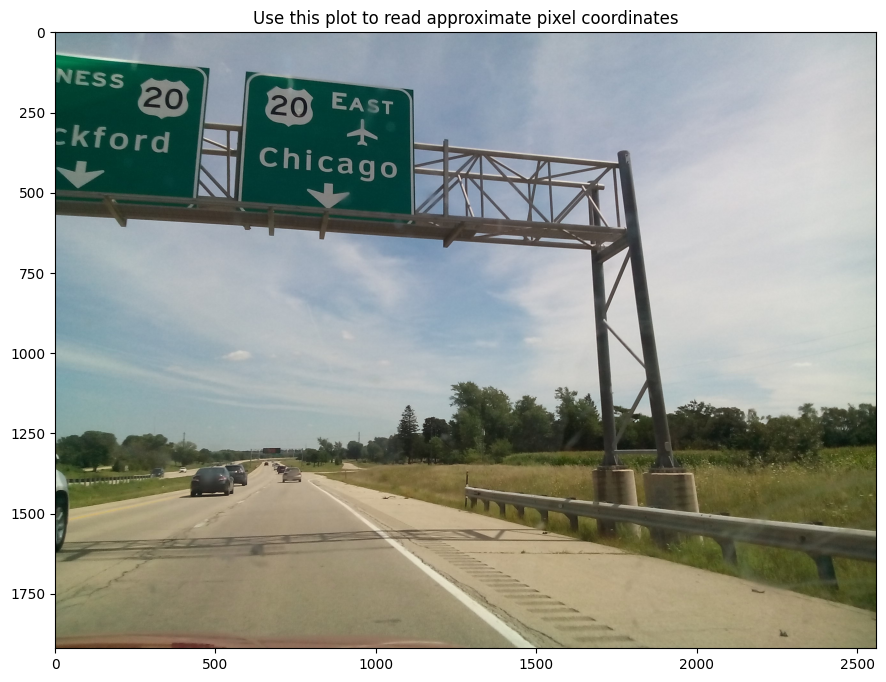

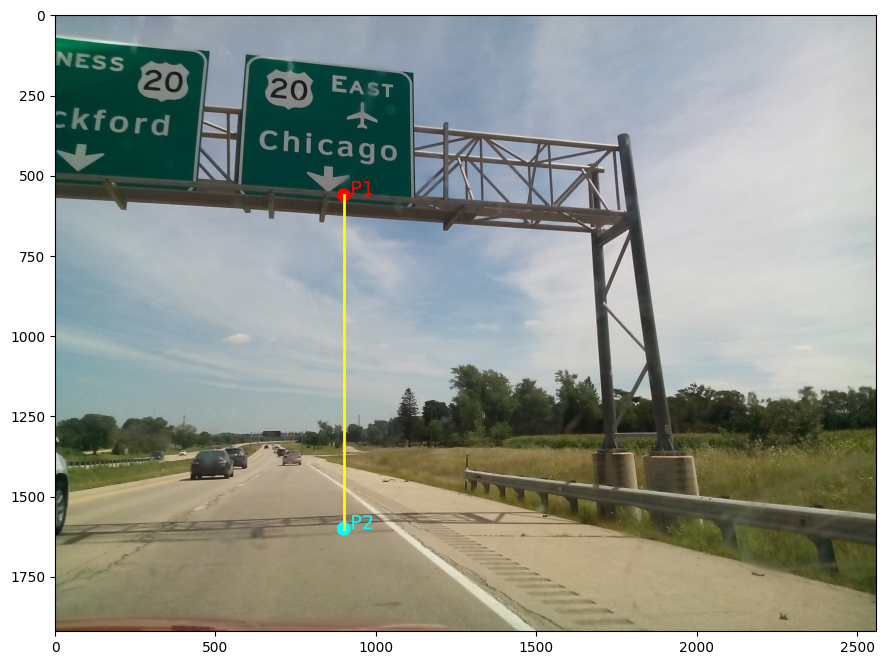

In [9]:
# Step 2: visualize image and define two measurement points
plt.figure(figsize=(12, 8))
plt.imshow(img_np)
plt.axis("on")
plt.title("Use this plot to read approximate pixel coordinates")
plt.show()

# Replace these with your selected points: (x, y)
p1 = (900, 560)
p2 = (900, 1600)

plt.figure(figsize=(12, 8))
plt.imshow(img_np)
plt.scatter([p1[0], p2[0]], [p1[1], p2[1]], c=["red", "cyan"], s=80)
plt.plot([p1[0], p2[0]], [p1[1], p2[1]], color="yellow", linewidth=2)
plt.text(p1[0], p1[1], " P1", color="red", fontsize=14)
plt.text(p2[0], p2[1], " P2", color="cyan", fontsize=14)
plt.axis("on")
plt.show()

In [10]:
print("p1 =", p1)
print("p2 =", p2)

p1 = (900, 560)
p2 = (900, 1600)


In [12]:
print("Original image shape:", img_np.shape)        # H, W, 3
print("World points shape:", world_points.shape)   # H, W, 3
print("Current p1:", p1)
print("Current p2:", p2)

H_img, W_img = img_np.shape[:2]
H_wp, W_wp = world_points.shape[:2]

print("Original W,H:", W_img, H_img)
print("MapAnything W,H:", W_wp, H_wp)

Original image shape: (1920, 2560, 3)
World points shape: (392, 518, 3)
Current p1: (900, 560)
Current p2: (900, 1600)
Original W,H: 2560 1920
MapAnything W,H: 518 392


In [13]:
# Convert original image coordinates to MapAnything output coordinates
def scale_point_to_ma(p_xy):
    x, y = p_xy

    H_img, W_img = img_np.shape[:2]
    H_ma, W_ma = world_points.shape[:2]

    x_ma = int(round(x * W_ma / W_img))
    y_ma = int(round(y * H_ma / H_img))

    x_ma = max(0, min(W_ma - 1, x_ma))
    y_ma = max(0, min(H_ma - 1, y_ma))

    return (x_ma, y_ma)

p1_ma = scale_point_to_ma(p1)
p2_ma = scale_point_to_ma(p2)

print("p1 original:", p1, "-> p1_ma:", p1_ma)
print("p2 original:", p2, "-> p2_ma:", p2_ma)

p1 original: (900, 560) -> p1_ma: (182, 114)
p2 original: (900, 1600) -> p2_ma: (182, 327)


In [15]:
# Find nearest valid MapAnything pixel if selected point is invalid
import numpy as np

def snap_to_nearest_valid(p_xy, valid_mask, max_radius=30):
    x, y = map(int, p_xy)
    H, W = valid_mask.shape

    if 0 <= x < W and 0 <= y < H and valid_mask[y, x]:
        return (x, y), 0

    for r in range(1, max_radius + 1):
        x0, x1 = max(0, x - r), min(W, x + r + 1)
        y0, y1 = max(0, y - r), min(H, y + r + 1)

        patch = valid_mask[y0:y1, x0:x1]
        ys, xs = np.where(patch)

        if len(xs) > 0:
            xs_global = xs + x0
            ys_global = ys + y0
            d2 = (xs_global - x) ** 2 + (ys_global - y) ** 2
            idx = np.argmin(d2)
            return (int(xs_global[idx]), int(ys_global[idx])), int(round(np.sqrt(d2[idx])))

    raise ValueError(f"No valid pixel found within radius {max_radius}. Pick another point.")

p1_safe, p1_shift = snap_to_nearest_valid(p1_ma, ma_mask, max_radius=40)
p2_safe, p2_shift = snap_to_nearest_valid(p2_ma, ma_mask, max_radius=40)

print("p1_ma:", p1_ma, "-> p1_safe:", p1_safe, "shift_px:", p1_shift)
print("p2_ma:", p2_ma, "-> p2_safe:", p2_safe, "shift_px:", p2_shift)

p1_ma: (182, 114) -> p1_safe: (182, 114) shift_px: 0
p2_ma: (182, 327) -> p2_safe: (183, 327) shift_px: 1


In [16]:
dist_no_sam_m, P1_no_sam, P2_no_sam = measure_direct_m(
    world_points, ma_mask, p1_safe, p2_safe
)

print("No SAM result")
print(f"Distance: {dist_no_sam_m:.3f} m")
print("P1 3D:", P1_no_sam)
print("P2 3D:", P2_no_sam)

No SAM result
Distance: 4.758 m
P1 3D: [-1.7702919 -1.9244431  7.85788  ]
P2 3D: [-1.6145765  2.793216   7.260777 ]


In [18]:
from PIL import Image
import numpy as np

# Resize original image to match MapAnything output size
H_ma, W_ma = world_points.shape[:2]

img_ma_np = np.array(
    Image.fromarray(img_np).resize((W_ma, H_ma))
)

print("img_np shape:", img_np.shape)
print("img_ma_np shape:", img_ma_np.shape)
print("world_points shape:", world_points.shape)
print("ma_mask shape:", ma_mask.shape)

img_np shape: (1920, 2560, 3)
img_ma_np shape: (392, 518, 3)
world_points shape: (392, 518, 3)
ma_mask shape: (392, 518)


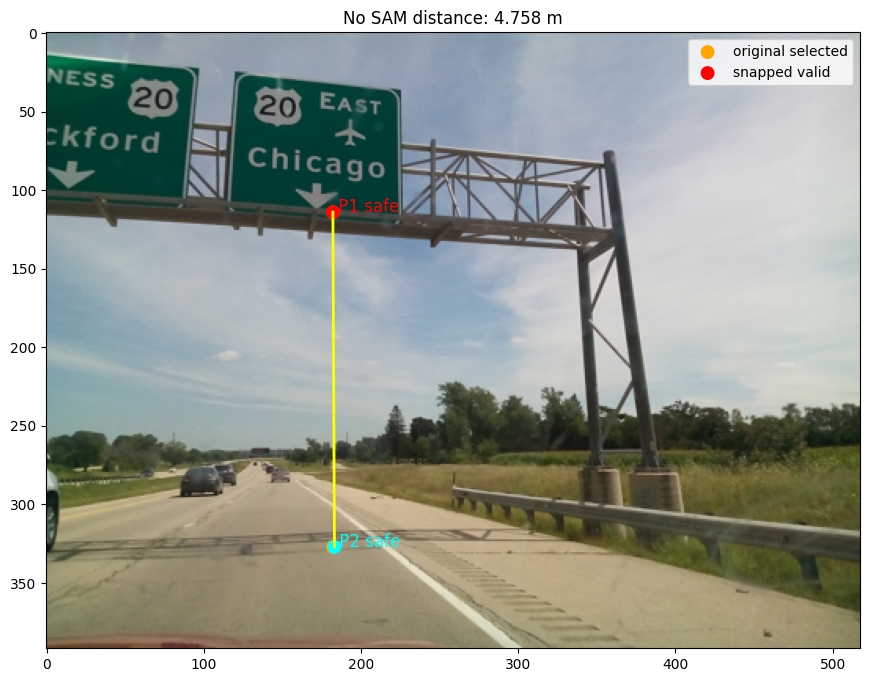

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
plt.imshow(img_ma_np)

plt.scatter(
    [p1_ma[0], p2_ma[0]],
    [p1_ma[1], p2_ma[1]],
    c=["orange", "orange"],
    s=80,
    label="original selected"
)

plt.scatter(
    [p1_safe[0], p2_safe[0]],
    [p1_safe[1], p2_safe[1]],
    c=["red", "cyan"],
    s=80,
    label="snapped valid"
)

plt.plot(
    [p1_safe[0], p2_safe[0]],
    [p1_safe[1], p2_safe[1]],
    color="yellow",
    linewidth=2
)

plt.text(p1_safe[0], p1_safe[1], " P1 safe", color="red", fontsize=12)
plt.text(p2_safe[0], p2_safe[1], " P2 safe", color="cyan", fontsize=12)

plt.title(f"No SAM distance: {dist_no_sam_m:.3f} m")
plt.legend()
plt.axis("on")
plt.show()

In [22]:
%cd /content
!pip install -q git+https://github.com/facebookresearch/segment-anything.git

import os
import requests
import torch
from segment_anything import sam_model_registry, SamPredictor

device = "cuda" if torch.cuda.is_available() else "cpu"

sam_ckpt = "/content/sam_vit_b_01ec64.pth"

if not os.path.exists(sam_ckpt):
    url = "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth"
    r = requests.get(url)
    r.raise_for_status()
    with open(sam_ckpt, "wb") as f:
        f.write(r.content)

sam = sam_model_registry["vit_b"](checkpoint=sam_ckpt).to(device)
sam.eval()

predictor = SamPredictor(sam)
predictor.set_image(img_ma_np)

print("SAM predictor loaded")

/content
  Preparing metadata (setup.py) ... done
SAM predictor loaded


In [27]:
# Define SAM-assisted local 3D point function
import numpy as np

def get_sam_local_3d_point(p_xy, radius_px=10):
    x, y = map(int, p_xy)

    masks, scores, logits = predictor.predict(
        point_coords=np.array([[x, y]]),
        point_labels=np.array([1]),
        multimask_output=True,
    )

    # Keep SAM masks that contain the clicked point
    candidates = []
    for m, s in zip(masks, scores):
        if m[y, x]:
            candidates.append((m.sum(), s, m))

    if len(candidates) == 0:
        raise ValueError("SAM did not return a mask containing the clicked point.")

    # Choose the smallest mask to avoid selecting too much background
    candidates.sort(key=lambda t: t[0])
    sam_mask = candidates[0][2]

    H, W = ma_mask.shape
    yy, xx = np.ogrid[:H, :W]

    local_circle = (xx - x) ** 2 + (yy - y) ** 2 <= radius_px ** 2
    final_mask = sam_mask & local_circle & ma_mask

    pts = world_points[final_mask]

    if len(pts) < 10:
        raise ValueError(
            f"Too few valid 3D points: {len(pts)}. "
            "Try radius_px=20 or choose another point."
        )

    point_3d = np.median(pts, axis=0)
    return point_3d, final_mask, sam_mask

print("get_sam_local_3d_point is ready")

get_sam_local_3d_point is ready


In [28]:
# Check which variables are already defined
required_vars = [
    "img_np",
    "world_points",
    "ma_mask",
    "p1",
    "p2",
    "p1_ma",
    "p2_ma",
    "p1_safe",
    "p2_safe",
    "img_ma_np",
    "predictor",
    "dist_no_sam_m",
]

for v in required_vars:
    print(f"{v:15s}:", "OK" if v in globals() else "MISSING")

img_np         : OK
world_points   : OK
ma_mask        : OK
p1             : OK
p2             : OK
p1_ma          : OK
p2_ma          : OK
p1_safe        : OK
p2_safe        : OK
img_ma_np      : OK
predictor      : OK
dist_no_sam_m  : OK


In [29]:
predictor.set_image(img_ma_np)

P1_sam, P1_local_mask, P1_sam_mask = get_sam_local_3d_point(p1_safe, radius_px=10)
P2_sam, P2_local_mask, P2_sam_mask = get_sam_local_3d_point(p2_safe, radius_px=10)

dist_sam_m = float(np.linalg.norm(P1_sam - P2_sam))

print("SAM-assisted result")
print(f"Distance: {dist_sam_m:.3f} m")
print("P1 SAM median 3D:", P1_sam)
print("P2 SAM median 3D:", P2_sam)

SAM-assisted result
Distance: 4.810 m
P1 SAM median 3D: [-1.8414072 -1.9252595  8.1448765]
P2 SAM median 3D: [-1.6031749  2.7999177  7.2781944]


In [31]:
# SAM-assisted measurement with snapped valid points
predictor.set_image(img_ma_np)

P1_sam, P1_local_mask, P1_sam_mask = get_sam_local_3d_point(p1_safe, radius_px=10)
P2_sam, P2_local_mask, P2_sam_mask = get_sam_local_3d_point(p2_safe, radius_px=10)

dist_sam_m = float(np.linalg.norm(P1_sam - P2_sam))

print("SAM-assisted result")
print(f"Distance: {dist_sam_m:.3f} m")
print("P1 SAM median 3D:", P1_sam)
print("P2 SAM median 3D:", P2_sam)

SAM-assisted result
Distance: 4.810 m
P1 SAM median 3D: [-1.8414072 -1.9252595  8.1448765]
P2 SAM median 3D: [-1.6031749  2.7999177  7.2781944]
